# Industrial Predictive Maintenance
## Notebook 03: Exploratory Data Analysis
Explore raw sensor measurements, machine lifetimes and degradation without changing the source data.

## 1. Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_PATH = Path("../data/raw")
if not DATA_PATH.is_dir():
    DATA_PATH = Path("data/raw")

readings = pd.read_csv(DATA_PATH / "readings.csv")
units = pd.read_csv(DATA_PATH / "units.csv")
ground_truth = pd.read_csv(DATA_PATH / "ground_truth.csv")

sensor_names = {
    "tool_wear_min": "Tool Wear (min)",
    "vibration_mm_s": "Vibration (mm/s)",
    "torque_nm": "Torque (Nm)",
    "process_temperature_k": "Process Temp (K)",
    "air_temperature_k": "Air Temp (K)",
    "rotational_speed_rpm": "Speed (rpm)"
}
sensors = list(sensor_names)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Keep held-out machines separate for model-related exploration.
train = readings[readings["split"] == "train"].copy()
print("Readings:", readings.shape)
print("Units:", units.shape)
print("Ground truth:", ground_truth.shape)
print("Training machines:", train["unit_id"].nunique())

Readings: (23118, 13)
Units: (100, 4)
Ground truth: (23118, 3)
Training machines: 80


## 2. Univariate Analysis
### 2.1 Sensor Distributions

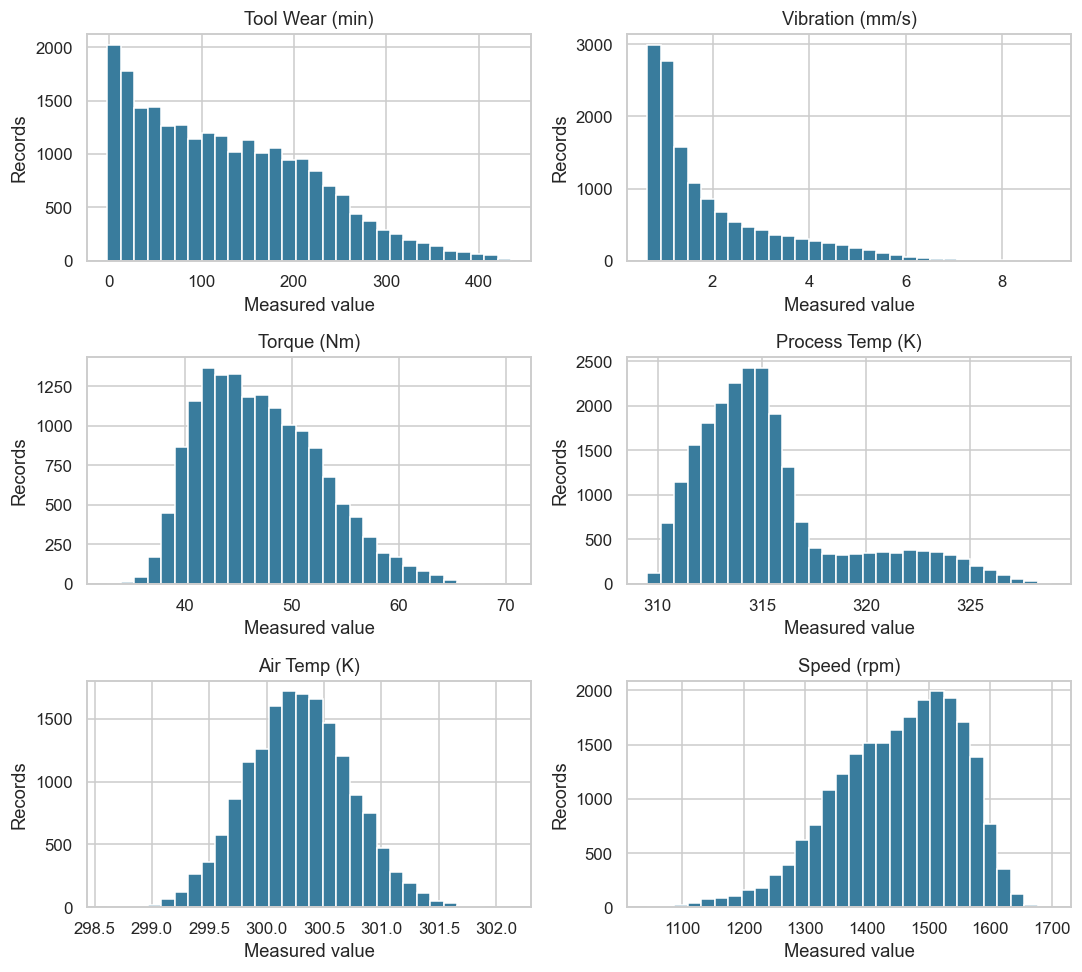

In [2]:
fig, axes = plt.subplots(3, 2, figsize=(10, 9))
for sensor, ax in zip(sensors, axes.flat):
    ax.hist(readings[sensor].dropna(), bins=30, color="#397C9D", edgecolor="white")
    ax.set_title(sensor_names[sensor])
    ax.set_ylabel("Records")
    ax.set_xlabel("Measured value")
fig.tight_layout()
plt.show()

### 2.2 IQR Outlier Detection

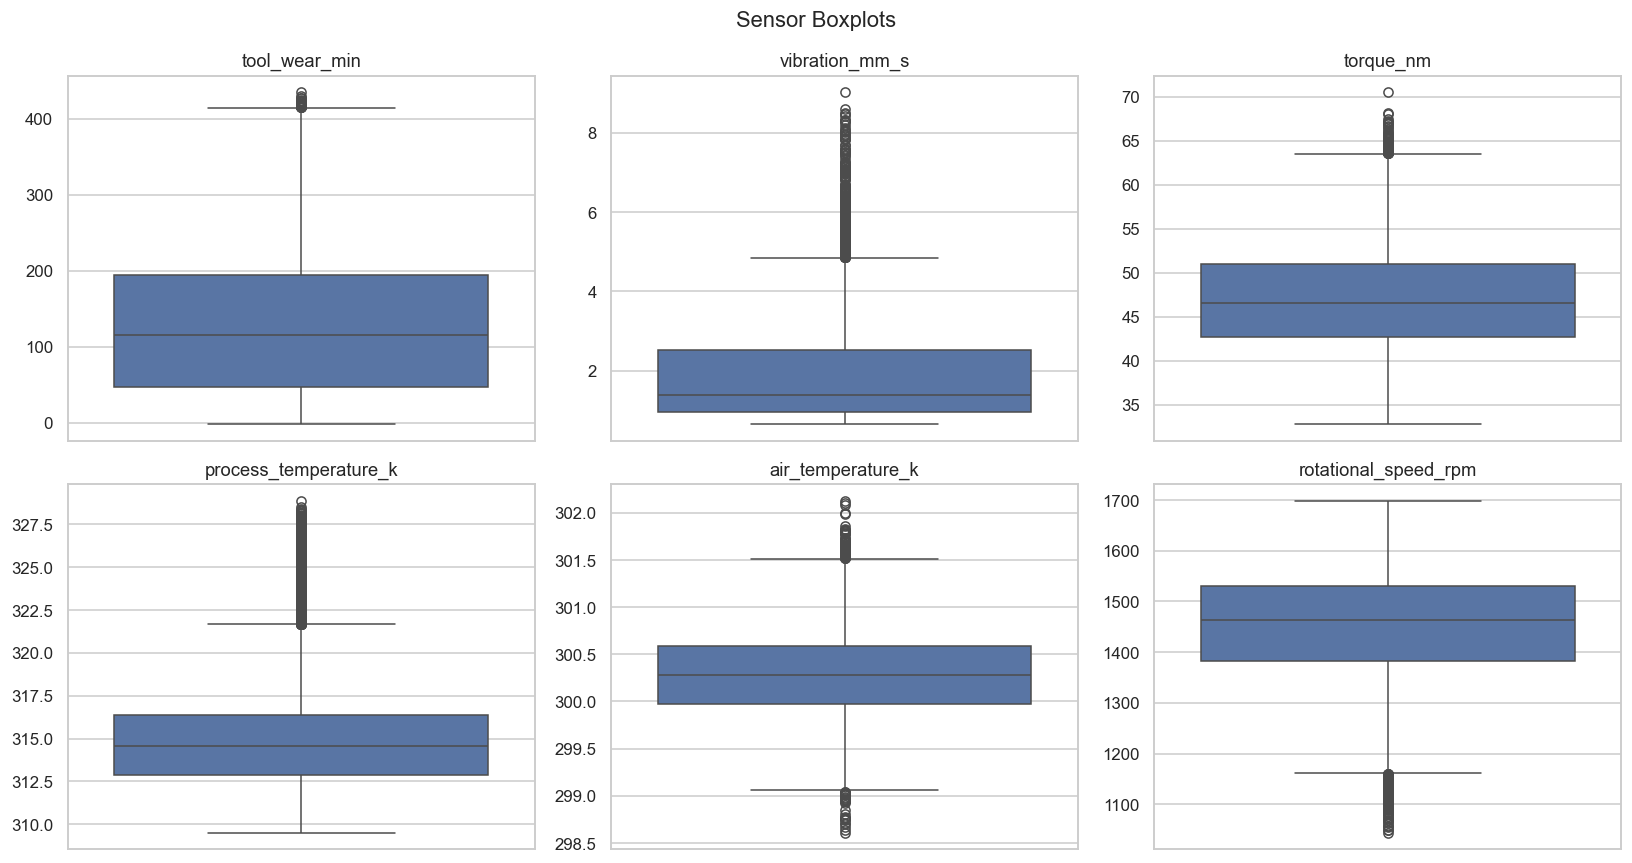

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for sensor, ax in zip(sensors, axes.flatten()):
    sns.boxplot(y=readings[sensor], ax=ax)
    ax.set_title(sensor)
    ax.set_ylabel("")

plt.suptitle("Sensor Boxplots")
plt.tight_layout()
plt.show()

In [13]:
outlier_results = []
for sensor in sensors:
    values = readings[sensor].dropna()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((values < lower) | (values > upper)).sum()
    outlier_results.append({
        "Sensor": sensor_names[sensor], "Q1": Q1, "Q3": Q3,
        "IQR": IQR, "Lower Bound": lower, "Upper Bound": upper,
        "Observed Count": len(values), "Outlier Count": count,
        "Outlier Percentage (%)": 100 * count / len(values) if len(values) else np.nan
    })
outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))


,Sensor,Q1,Q3,IQR,Lower Bound,Upper Bound,Observed Count,Outlier Count,Outlier Percentage (%)
0,Tool Wear (min),47.00,194.00,147.00,-173.50,414.50,23118,33,0.14
1,Vibration (mm/s),0.96,2.52,1.56,-1.37,4.85,13771,647,4.70
2,Torque (Nm),42.68,51.02,8.34,30.17,63.53,15617,65,0.42
3,Process Temp (K),312.89,316.40,3.51,307.62,321.66,23118,2323,10.05
4,Air Temp (K),299.97,300.59,0.62,299.04,301.52,16848,98,0.58
5,Speed (rpm),1383.00,1531.00,148.00,1161.00,1753.00,23118,170,0.74


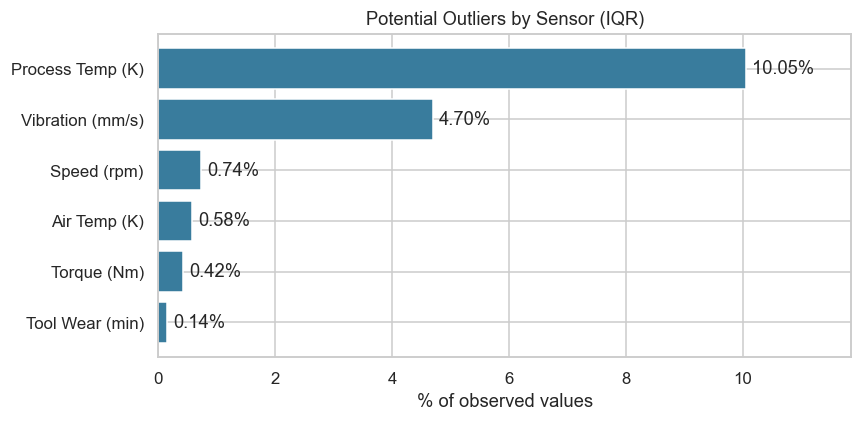

In [14]:

plot_data = outlier_summary.sort_values("Outlier Percentage (%)")
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(plot_data["Sensor"], plot_data["Outlier Percentage (%)"], color="#397C9D")
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.margins(x=0.18)
ax.set(xlabel="% of observed values", title="Potential Outliers by Sensor (IQR)")
fig.tight_layout()
plt.show()

IQR flags statistical extremes, not necessarily errors. Missing values are excluded from the denominator.

### 2.3 Failure Mode Distribution

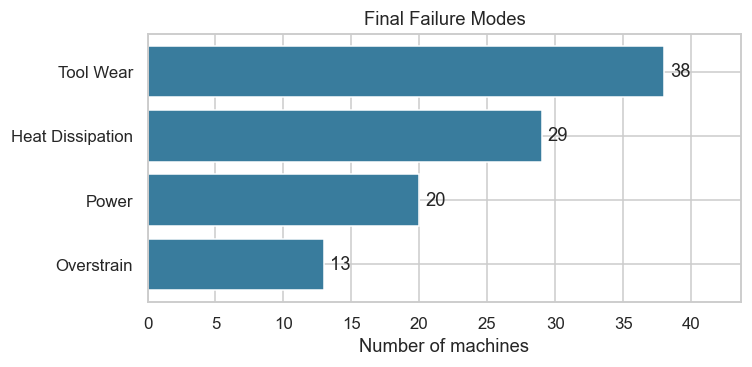

In [4]:
mode_counts = units["failure_mode"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(mode_counts.index.str.replace("_", " ").str.title(), mode_counts.values, color="#397C9D")
ax.bar_label(bars, padding=4)
ax.margins(x=0.15)
ax.set(xlabel="Number of machines", title="Final Failure Modes")
fig.tight_layout()
plt.show()

### 2.4 Machine Lifetime Distribution

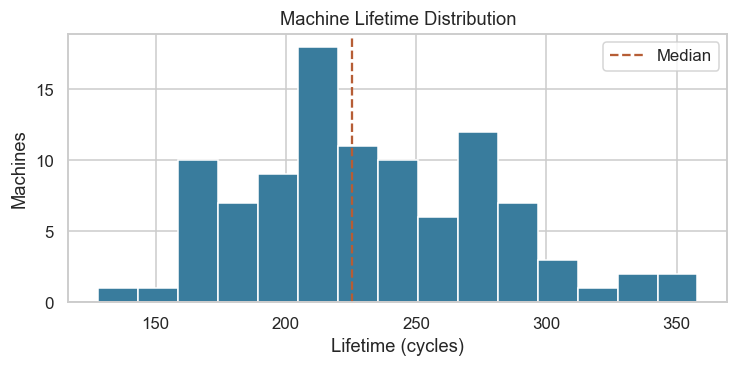

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(units["life_cycles"], bins=15, color="#397C9D", edgecolor="white")
ax.axvline(units["life_cycles"].median(), color="#B65D35", linestyle="--", label="Median")
ax.set(xlabel="Lifetime (cycles)", ylabel="Machines", title="Machine Lifetime Distribution")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Correlation Analysis
Model-related analysis uses training machines only. Correlations use available pairs without imputation.
### 3.1 Correlation Matrix

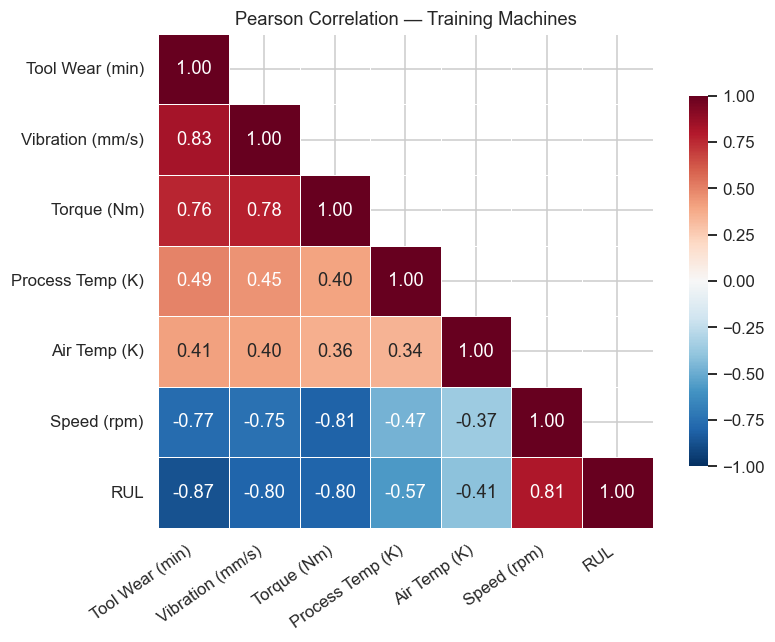

In [6]:
correlation_data = train[sensors + ["rul_cycles"]].rename(columns={**sensor_names, "rul_cycles": "RUL"})
correlation_matrix = correlation_data.corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=.5,
            cbar_kws={"shrink": .75}, ax=ax)
ax.set_title("Pearson Correlation — Training Machines")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
fig.tight_layout()
plt.show()

### 3.2 Sensor Correlation with RUL

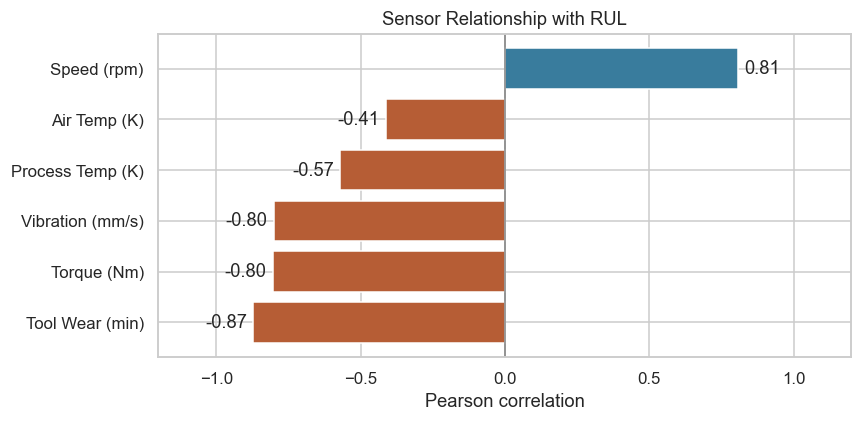

,Correlation with RUL,Paired observations
Air Temp (K),-0.413,13680
Process Temp (K),-0.570,18801
Speed (rpm),0.806,18801
Tool Wear (min),-0.872,18801
Torque (Nm),-0.804,12742
Vibration (mm/s),-0.800,11180


In [7]:
rul_correlation = correlation_matrix["RUL"].drop("RUL").sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#B65D35" if value < 0 else "#397C9D" for value in rul_correlation]
bars = ax.barh(rul_correlation.index, rul_correlation.values, color=colors)
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.axvline(0, color="gray", linewidth=1)
ax.set(xlim=(-1.2, 1.2), xlabel="Pearson correlation", title="Sensor Relationship with RUL")
fig.tight_layout()
plt.show()

# Different sensors have different numbers of available observations.
display(pd.DataFrame({"Correlation with RUL": rul_correlation,
                      "Paired observations": correlation_data.drop(columns="RUL").notna().mul(correlation_data["RUL"].notna(), axis=0).sum()}).round(3))

## 4. Time-Series Analysis
### 4.1 Sensor Behavior as Failure Approaches
Median measurements in 25-cycle RUL bands; no missing values are filled.

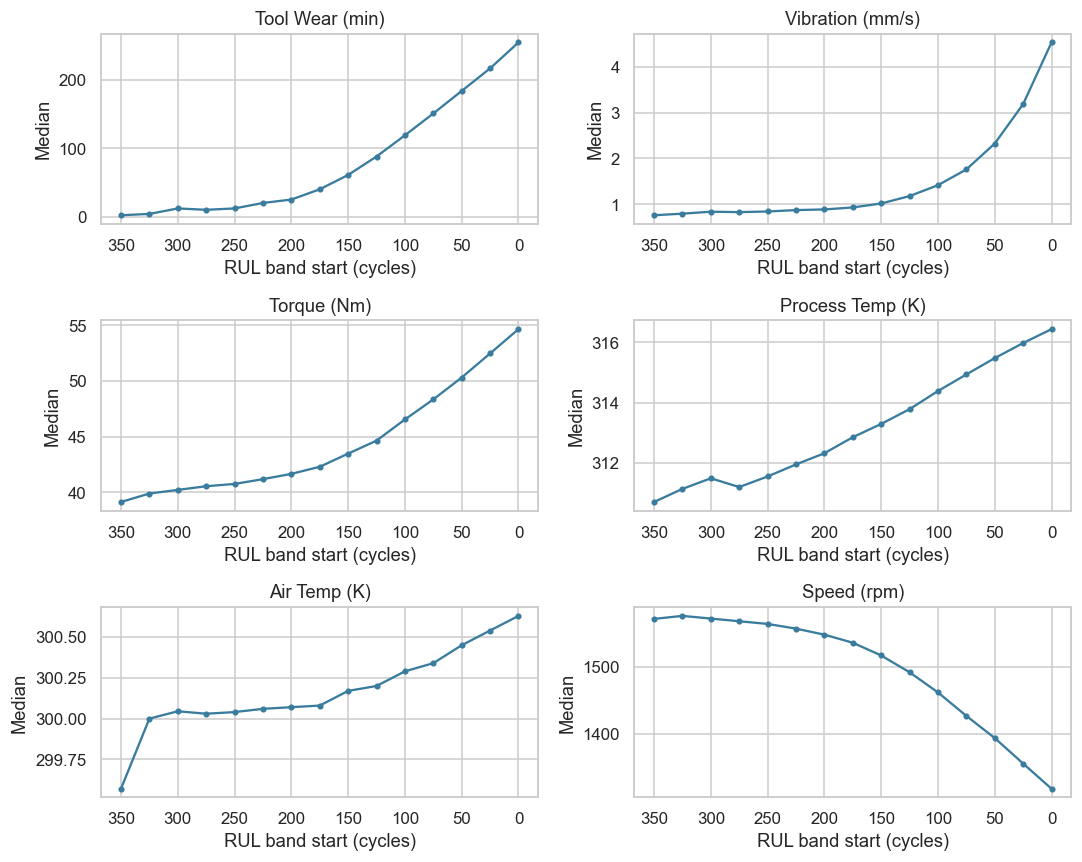

In [8]:
rul_bands = train.assign(rul_band=(train["rul_cycles"] // 25) * 25)
trend = rul_bands.groupby("rul_band")[sensors].median().sort_index()
fig, axes = plt.subplots(3, 2, figsize=(10, 8))
for sensor, ax in zip(sensors, axes.flat):
    ax.plot(trend.index, trend[sensor], marker="o", markersize=3, color="#397C9D")
    ax.invert_xaxis()
    ax.set_title(sensor_names[sensor])
    ax.set_xlabel("RUL band start (cycles)")
    ax.set_ylabel("Median")
fig.tight_layout()
plt.show()

### 4.2 Damage Progression
Three representative training machines with short, median and long lifetimes; damage is a reference label, not an input feature.

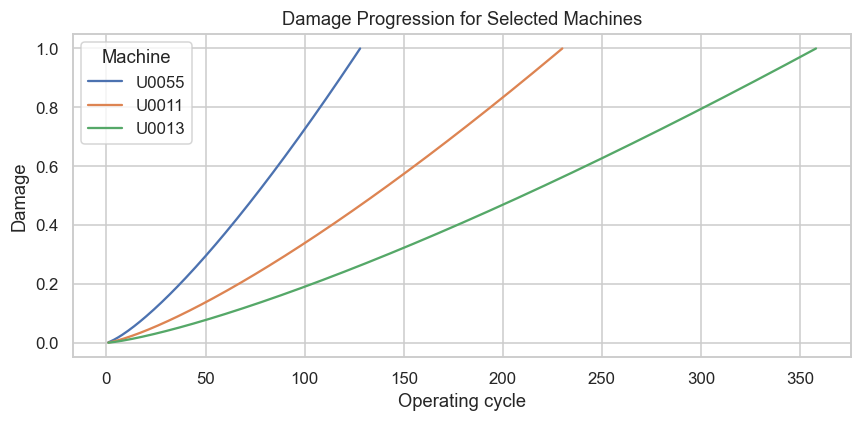

In [9]:
ordered_units = units[units["split"] == "train"].sort_values("life_cycles")
selected_units = ordered_units.iloc[[0, len(ordered_units)//2, -1]]["unit_id"].unique()
fig, ax = plt.subplots(figsize=(8, 4))
for unit in selected_units:
    machine = ground_truth[ground_truth["unit_id"] == unit].sort_values("cycle")
    ax.plot(machine["cycle"], machine["damage"], label=unit)
ax.set(xlabel="Operating cycle", ylabel="Damage", title="Damage Progression for Selected Machines")
ax.legend(title="Machine")
fig.tight_layout()
plt.show()

## 5. Final Findings

In [10]:
# Generate a concise summary from the actual loaded files.
print(f"Machines: {units['unit_id'].nunique()}")
print(f"Lifetime range: {units['life_cycles'].min()}–{units['life_cycles'].max()} cycles")
print(f"Median lifetime: {units['life_cycles'].median():.1f} cycles")
print(f"Most frequent final failure mode: {units['failure_mode'].value_counts().idxmax()}")
most_outliers = outlier_summary.loc[outlier_summary["Outlier Percentage (%)"].idxmax()]
print(f"Highest IQR outlier rate: {most_outliers['Sensor']} ({most_outliers['Outlier Percentage (%)']:.2f}%)")
strongest = rul_correlation.abs().idxmax()
print(f"Strongest absolute Pearson relationship with RUL (training): {strongest} ({rul_correlation[strongest]:.3f})")

Machines: 100
Lifetime range: 128–358 cycles
Median lifetime: 225.5 cycles
Most frequent final failure mode: tool_wear
Highest IQR outlier rate: Process Temp (K) (10.05%)
Strongest absolute Pearson relationship with RUL (training): Tool Wear (min) (-0.872)


The dataset is synthetic. Correlation does not establish causation, and IQR flags do not establish measurement errors. Raw files remain unchanged; treatment decisions belong to the cleaning stage.